In [ ]:
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

import sys

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate the project root containing src/")
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.models import SiameseNetwork
from src.losses import contrastive_loss

In [ ]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


In [ ]:
NORMALIZED_DIR = (
    PROJECT_ROOT
    / "datasets"
    / "normalized"
)

classes = ["normal", "irf", "orf"]

X_list = []
y_list = []

for label, class_name in enumerate(classes):

    X_class = np.loadtxt(
        NORMALIZED_DIR / f"{class_name}.csv",
        delimiter=","
    ).astype(np.float32)

    X_list.append(X_class)

    y_list.extend(
        [label] * len(X_class)
    )

X = np.concatenate(X_list, axis=0)

y = np.asarray(y_list)

print("X:", X.shape)
print("y:", y.shape)

X: (300, 100000)
y: (300,)


In [ ]:
split = np.load(
    PROJECT_ROOT
    / "results"
    / "fsl_split.npz"
)

train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 210
Validation: 45
Test: 45


In [ ]:
class SiamesePairDataset(Dataset):

    def __init__(
        self,
        X,
        y,
        indices,
        pairs_per_signal=4
    ):

        self.X = X
        self.y = y

        self.indices = np.asarray(
            indices
        )

        self.pairs = []

        rng = np.random.default_rng(42)

        for idx in self.indices:

            current_class = y[idx]

            # -------------------------
            # Positive pairs
            # -------------------------

            same_class = self.indices[
                y[self.indices] == current_class
            ]

            for _ in range(pairs_per_signal):

                other = rng.choice(
                    same_class
                )

                self.pairs.append(
                    (idx, other, 1.0)
                )

            # -------------------------
            # Negative pairs
            # -------------------------

            different_class = self.indices[
                y[self.indices] != current_class
            ]

            for _ in range(pairs_per_signal):

                other = rng.choice(
                    different_class
                )

                self.pairs.append(
                    (idx, other, 0.0)
                )

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):

        idx1, idx2, label = self.pairs[index]

        x1 = torch.from_numpy(
            self.X[idx1]
        ).float()

        x2 = torch.from_numpy(
            self.X[idx2]
        ).float()

        # Conv1D expects:
        # [channels, sequence_length]

        x1 = x1.unsqueeze(0)
        x2 = x2.unsqueeze(0)

        label = torch.tensor(
            label,
            dtype=torch.float32
        )

        return x1, x2, label

In [ ]:
train_dataset = SiamesePairDataset(
    X,
    y,
    train_idx
)

val_dataset = SiamesePairDataset(
    X,
    y,
    val_idx
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

print(
    "Training pairs:",
    len(train_dataset)
)

print(
    "Validation pairs:",
    len(val_dataset)
)

Training pairs: 1680
Validation pairs: 360


In [ ]:
model = SiameseNetwork(
    embedding_dim=128
).to(DEVICE)

print(model)

SiameseNetwork(
  (encoder): Conv1DEncoder(
    (features): Sequential(
      (0): Conv1d(1, 32, kernel_size=(9,), stride=(1,), padding=(4,))
      (1): ReLU()
      (2): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
      (3): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
      (4): ReLU()
      (5): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
      (6): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
      (7): ReLU()
      (8): AdaptiveAvgPool1d(output_size=1)
    )
    (embedding): Linear(in_features=128, out_features=128, bias=True)
  )
)


In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

In [ ]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    device
):

    model.train()

    total_loss = 0.0

    for x1, x2, label in loader:

        x1 = x1.to(device)
        x2 = x2.to(device)
        label = label.to(device)

        optimizer.zero_grad()

        # Siamese forward pass
        z1, z2 = model(x1, x2)

        # THIS is where your function is used
        loss = contrastive_loss(
            z1,
            z2,
            label
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [ ]:
def validate(
    model,
    loader,
    device
):

    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        for x1, x2, label in loader:

            x1 = x1.to(device)
            x2 = x2.to(device)
            label = label.to(device)

            z1, z2 = model(
                x1,
                x2
            )

            loss = contrastive_loss(
                z1,
                z2,
                label
            )

            total_loss += loss.item()

    return total_loss / len(loader)

In [ ]:
EPOCHS = 20

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

CHECKPOINT_PATH = MODEL_DIR / "fsl_conv1d_best.pt"

if CHECKPOINT_PATH.exists():

    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    if "optimizer_state_dict" in checkpoint:
        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

    best_val_loss = checkpoint.get(
        "val_loss",
        float("inf")
    )

    print(
        "Existing checkpoint loaded; training skipped."
    )
    print(
        "Checkpoint epoch:",
        checkpoint.get("epoch", "unknown")
    )
    print(
        "Validation loss:",
        best_val_loss
    )

else:

    best_val_loss = float("inf")

    for epoch in range(1, EPOCHS + 1):

        train_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            DEVICE
        )

        val_loss = validate(
            model,
            val_loader,
            DEVICE
        )

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train loss: {train_loss:.6f} | "
            f"Val loss: {val_loss:.6f}"
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "val_loss": val_loss
                },
                CHECKPOINT_PATH
            )

            print("  checkpoint saved")

Existing checkpoint loaded; training skipped.
Checkpoint epoch: 17
Validation loss: 0.002245161373613645


In [ ]:
checkpoint_path = (
    PROJECT_ROOT
    / "models"
    / "fsl_conv1d_best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Checkpoint loaded.")
print("Epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["val_loss"])

Checkpoint loaded.
Epoch: 17
Validation loss: 0.002245161373613645


In [ ]:
import numpy as np
import torch


def compute_prototypes(
    support_embeddings,
    support_labels
):
    """
    Compute one prototype per class.

    Prototype = mean embedding of the support examples
    belonging to that class.
    """

    classes = np.unique(support_labels)

    prototypes = []

    for class_id in classes:

        class_embeddings = support_embeddings[
            support_labels == class_id
        ]

        prototype = class_embeddings.mean(
            axis=0
        )

        prototypes.append(prototype)

    return np.stack(prototypes)


def classify_queries(
    query_embeddings,
    prototypes
):
    """
    Classify queries using Euclidean distance
    to class prototypes.
    """

    distances = np.linalg.norm(
        query_embeddings[:, None, :]
        - prototypes[None, :, :],
        axis=2
    )

    predictions = np.argmin(
        distances,
        axis=1
    )

    return predictions, distances

In [ ]:
import numpy as np
import torch


def compute_prototypes(
    support_embeddings,
    support_labels
):
    """
    Compute one prototype per class.

    Prototype = mean embedding of the support examples
    belonging to that class.
    """

    classes = np.unique(support_labels)

    prototypes = []

    for class_id in classes:

        class_embeddings = support_embeddings[
            support_labels == class_id
        ]

        prototype = class_embeddings.mean(
            axis=0
        )

        prototypes.append(prototype)

    return np.stack(prototypes)


def classify_queries(
    query_embeddings,
    prototypes
):
    """
    Classify queries using Euclidean distance
    to class prototypes.
    """

    distances = np.linalg.norm(
        query_embeddings[:, None, :]
        - prototypes[None, :, :],
        axis=2
    )

    predictions = np.argmin(
        distances,
        axis=1
    )

    return predictions, distances

In [ ]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate the project root containing src/")
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.fsl import (
    create_episode,
    get_embeddings
)

rng = np.random.default_rng(123)

episode = create_episode(
    indices=test_idx,
    labels=y,
    n_way=3,
    k_shot=5,
    query_per_class=5,
    rng=rng
)

print("Support indices:", episode.support_indices)
print("Query indices:", episode.query_indices)

print(
    "Support labels:",
    episode.support_labels
)

print(
    "Query labels:",
    episode.query_labels
)

Support indices: [269 290 295 280 298  48   1  98  59  37 177 111 132 172 100]
Query indices: [252 210 268 267 258  51  74  82  79  23 106 122 194 143 197]
Support labels: [0 0 0 0 0 1 1 1 1 1 2 2 2 2 2]
Query labels: [0 0 0 0 0 1 1 1 1 1 2 2 2 2 2]


In [ ]:
import importlib

import src.fsl as fsl

fsl = importlib.reload(fsl)
get_embeddings = fsl.get_embeddings

support_embeddings = get_embeddings(
    model,
    X,
    episode.support_indices,
    DEVICE
)

query_embeddings = get_embeddings(
    model,
    X,
    episode.query_indices,
    DEVICE
)

print(
    "Support embeddings:",
    support_embeddings.shape
)

print(
    "Query embeddings:",
    query_embeddings.shape
)

Support embeddings: (15, 128)
Query embeddings: (15, 128)


In [ ]:
prototypes = compute_prototypes(
    support_embeddings,
    episode.support_labels
)

predictions, distances = classify_queries(
    query_embeddings,
    prototypes
)

print("True:")
print(episode.query_labels)

print("Predicted:")
print(predictions)

True:
[0 0 0 0 0 1 1 1 1 1 2 2 2 2 2]
Predicted:
[0 0 0 0 0 1 1 1 1 1 2 2 2 2 2]


In [45]:
from src.evaluation import evaluate_predictions


def evaluate_fsl(
    model,
    X,
    y,
    test_idx,
    k_shot,
    n_episodes=100,
    query_per_class=5,
    seed=42
):

    rng = np.random.default_rng(seed)

    all_true = []
    all_pred = []
    all_distances = []

    for episode_number in range(
        n_episodes
    ):

        episode = create_episode(
            indices=test_idx,
            labels=y,
            n_way=3,
            k_shot=k_shot,
            query_per_class=query_per_class,
            rng=rng
        )

        support_embeddings = get_embeddings(
            model,
            X,
            episode.support_indices,
            DEVICE
        )

        query_embeddings = get_embeddings(
            model,
            X,
            episode.query_indices,
            DEVICE
        )

        prototypes = compute_prototypes(
            support_embeddings,
            episode.support_labels
        )

        predictions, distances = (
            classify_queries(
                query_embeddings,
                prototypes
            )
        )

        all_true.extend(
            episode.query_labels
        )

        all_pred.extend(
            predictions
        )

        all_distances.extend(
            distances
        )

    all_true = np.asarray(
        all_true
    )

    all_pred = np.asarray(
        all_pred
    )

    all_distances = np.asarray(
        all_distances
    )

    results = evaluate_predictions(
        all_true,
        all_pred,
        all_distances
    )

    results["y_true"] = all_true
    results["y_pred"] = all_pred
    results["distances"] = all_distances

    return results

In [46]:
results_1shot = evaluate_fsl(
    model=model,
    X=X,
    y=y,
    test_idx=test_idx,
    k_shot=1,
    n_episodes=100,
    query_per_class=5,
    seed=42
)

print(
    "1-shot Accuracy:",
    results_1shot["accuracy"]
)

print(
    "1-shot F1:",
    results_1shot["f1"]
)

print(
    "1-shot AUC:",
    results_1shot["auc"]
)

1-shot Accuracy: 1.0
1-shot F1: 1.0
1-shot AUC: 1.0


In [47]:
results_5shot = evaluate_fsl(
    model=model,
    X=X,
    y=y,
    test_idx=test_idx,
    k_shot=5,
    n_episodes=100,
    query_per_class=5,
    seed=42
)

print(
    "5-shot Accuracy:",
    results_5shot["accuracy"]
)

print(
    "5-shot F1:",
    results_5shot["f1"]
)

print(
    "5-shot AUC:",
    results_5shot["auc"]
)

5-shot Accuracy: 1.0
5-shot F1: 1.0
5-shot AUC: 1.0


In [48]:
results_5shot = evaluate_fsl(
    model=model,
    X=X,
    y=y,
    test_idx=test_idx,
    k_shot=5,
    n_episodes=100,
    query_per_class=5,
    seed=42
)

print(
    "5-shot Accuracy:",
    results_5shot["accuracy"]
)

print(
    "5-shot F1:",
    results_5shot["f1"]
)

print(
    "5-shot AUC:",
    results_5shot["auc"]
)

5-shot Accuracy: 1.0
5-shot F1: 1.0
5-shot AUC: 1.0


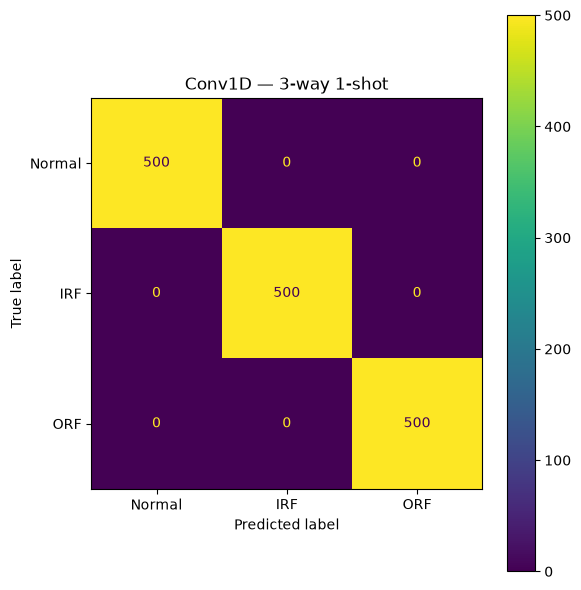

In [50]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

class_names = [
    "Normal",
    "IRF",
    "ORF"
]

fig, ax = plt.subplots(
    figsize=(6, 6)
)

ConfusionMatrixDisplay(
    results_1shot["confusion_matrix"],
    display_labels=class_names
).plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "Conv1D — 3-way 1-shot"
)

plt.tight_layout()
plt.show()

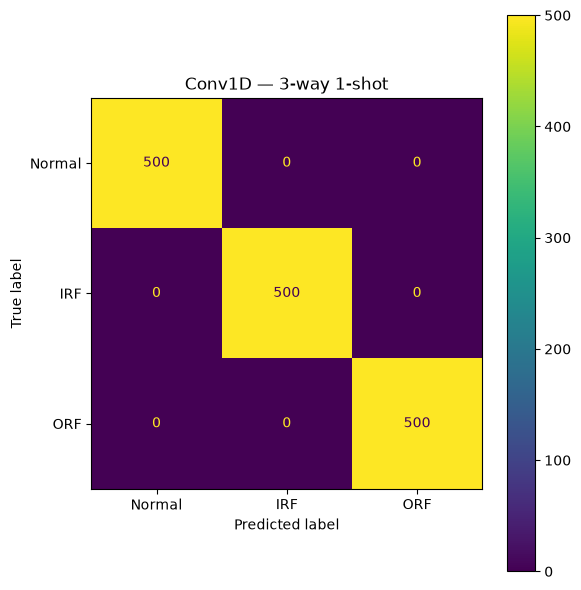

In [49]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

class_names = [
    "Normal",
    "IRF",
    "ORF"
]

fig, ax = plt.subplots(
    figsize=(6, 6)
)

ConfusionMatrixDisplay(
    results_1shot["confusion_matrix"],
    display_labels=class_names
).plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "Conv1D — 3-way 1-shot"
)

plt.tight_layout()
plt.show()

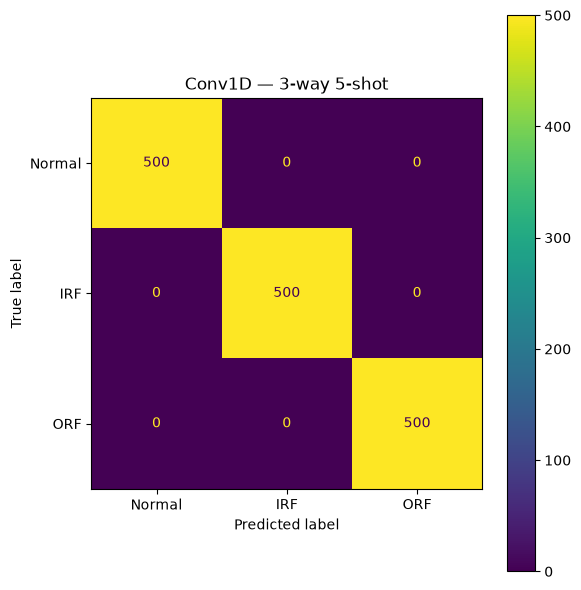

In [51]:
fig, ax = plt.subplots(
    figsize=(6, 6)
)

ConfusionMatrixDisplay(
    results_5shot["confusion_matrix"],
    display_labels=class_names
).plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "Conv1D — 3-way 5-shot"
)

plt.tight_layout()
plt.show()

In [54]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

def plot_roc(
    y_true,
    probabilities,
    title
):

    y_binary = label_binarize(
        y_true,
        classes=[0, 1, 2]
    )

    plt.figure(figsize=(7, 6))

    for class_id, class_name in enumerate(
        ["Normal", "IRF", "ORF"]
    ):

        fpr, tpr, _ = roc_curve(
            y_binary[:, class_id],
            probabilities[:, class_id]
        )

        class_auc = auc(
            fpr,
            tpr
        )

        plt.plot(
            fpr,
            tpr,
            label=f"{class_name} AUC={class_auc:.3f}"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title(title)

    plt.legend()
    plt.grid(True)

    plt.show()

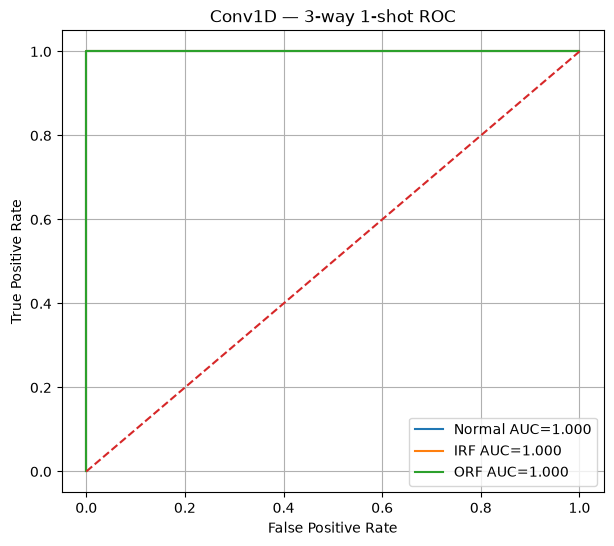

In [55]:
plot_roc(
    results_1shot["y_true"],
    results_1shot["probabilities"],
    "Conv1D — 3-way 1-shot ROC"
)

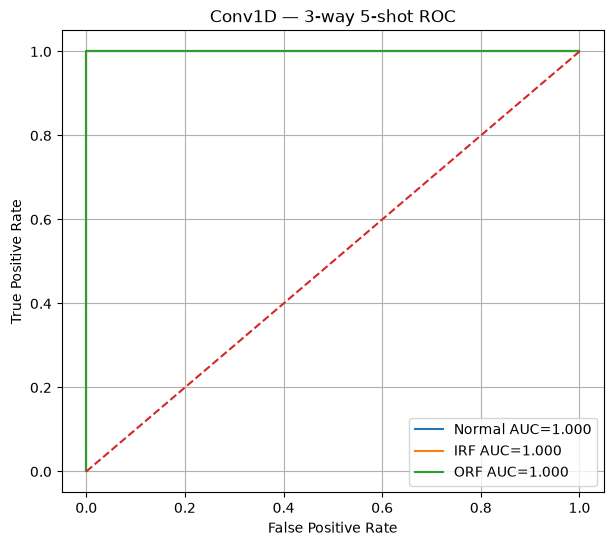

In [56]:
plot_roc(
    results_5shot["y_true"],
    results_5shot["probabilities"],
    "Conv1D — 3-way 5-shot ROC"
)

In [ ]:
import json

RESULTS_DIR = (
    PROJECT_ROOT / "results"
)

conv1d_summary = {
    "representation": "normalized_1D",
    "model": "Siamese Conv1D",
    "1_shot": {
        "accuracy": results_1shot["accuracy"],
        "f1": results_1shot["f1"],
        "auc": results_1shot["auc"]
    },
    "5_shot": {
        "accuracy": results_5shot["accuracy"],
        "f1": results_5shot["f1"],
        "auc": results_5shot["auc"]
    }
}

with open(
    RESULTS_DIR / "conv1d_fsl_results.json",
    "w"
) as f:

    json.dump(
        conv1d_summary,
        f,
        indent=4
    )

print("Conv1D results saved.")

Conv1D results saved.


: 

In [2]:
from pathlib import Path
import numpy as np

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate project root")
    PROJECT_ROOT = PROJECT_ROOT.parent

split = np.load(PROJECT_ROOT / "results" / "fsl_split.npz")

train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]

classes = ["normal", "irf", "orf"]
y = np.concatenate([
    np.full(
        len(np.loadtxt(
            PROJECT_ROOT / "datasets" / "normalized" / f"{class_name}.csv",
            delimiter=","
        )),
        label
    )
    for label, class_name in enumerate(classes)
])

print("TRAIN")
print("Number of samples:", len(train_idx))
print("Classes:", np.bincount(y[train_idx].astype(int)))

print("\nVALIDATION")
print("Number of samples:", len(val_idx))
print("Classes:", np.bincount(y[val_idx].astype(int)))

print("\nTEST")
print("Number of samples:", len(test_idx))
print("Classes:", np.bincount(y[test_idx].astype(int)))

print("\nOverlap checks")
print("Train ∩ Validation:", len(set(train_idx) & set(val_idx)))
print("Train ∩ Test:", len(set(train_idx) & set(test_idx)))
print("Validation ∩ Test:", len(set(val_idx) & set(test_idx)))

TRAIN
Number of samples: 210
Classes: [70 70 70]

VALIDATION
Number of samples: 45
Classes: [15 15 15]

TEST
Number of samples: 45
Classes: [15 15 15]

Overlap checks
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate project root")
    PROJECT_ROOT = PROJECT_ROOT.parent

NORMALIZED_DIR = PROJECT_ROOT / "datasets" / "normalized"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"

CLASS_NAMES = ["normal", "irf", "orf"]

# ---------------------------------------------------------
# Load normalized databases
# ---------------------------------------------------------

X_list = []
y_list = []

for class_id, class_name in enumerate(CLASS_NAMES):

    path = NORMALIZED_DIR / f"{class_name}.csv"

    X_class = pd.read_csv(
        path,
        header=None
    ).values.astype(np.float32)

    y_class = np.full(
        len(X_class),
        class_id,
        dtype=np.int64
    )

    X_list.append(X_class)
    y_list.append(y_class)

X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

print("=" * 70)
print("1D DATASET AUDIT")
print("=" * 70)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_id} ({class_name}):",
        np.sum(y == class_id)
    )

print("\nGlobal min:", X.min())
print("Global max:", X.max())

print("\nAny NaN:", np.isnan(X).any())
print("Any Inf:", np.isinf(X).any())

# Check every signal independently
row_min = X.min(axis=1)
row_max = X.max(axis=1)

print("\nRow-wise normalization check:")
print("Minimum row minimum:", row_min.min())
print("Maximum row minimum:", row_min.max())
print("Minimum row maximum:", row_max.min())
print("Maximum row maximum:", row_max.max())

print("\nAll rows start at 0:",
      np.allclose(row_min, 0.0))

print("All rows reach 1:",
      np.allclose(row_max, 1.0))

1D DATASET AUDIT
X shape: (300, 100000)
y shape: (300,)

Class distribution:
0 (normal): 100
1 (irf): 100
2 (orf): 100

Global min: 0.0
Global max: 1.0

Any NaN: False
Any Inf: False

Row-wise normalization check:
Minimum row minimum: 0.0
Maximum row minimum: 0.0
Minimum row maximum: 1.0
Maximum row maximum: 1.0

All rows start at 0: True
All rows reach 1: True


In [3]:
# ============================================================
# 1D SPLIT / LEAKAGE AUDIT
# ============================================================

split_path = RESULTS_DIR / "fsl_split.npz"

split = np.load(split_path)

train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]
split_y = split["y"]

print("=" * 70)
print("1D SPLIT / LEAKAGE AUDIT")
print("=" * 70)

print("\nNumber of samples:")
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

print("\nClass distributions:")

for name, indices in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    counts = np.bincount(y[indices], minlength=3)
    print(
        f"{name}: "
        f"Normal={counts[0]}, "
        f"IRF={counts[1]}, "
        f"ORF={counts[2]}"
    )

# ------------------------------------------------------------
# Check overlaps
# ------------------------------------------------------------

train_set = set(train_idx.tolist())
val_set = set(val_idx.tolist())
test_set = set(test_idx.tolist())

print("\nIndex overlap:")
print("Train ∩ Validation:", len(train_set & val_set))
print("Train ∩ Test:", len(train_set & test_set))
print("Validation ∩ Test:", len(val_set & test_set))

# ------------------------------------------------------------
# Verify that saved labels match current labels
# ------------------------------------------------------------

print("\nSaved labels match current labels:",
      np.array_equal(split_y, y))

# ------------------------------------------------------------
# Show actual indices
# ------------------------------------------------------------

print("\nFirst 10 train indices:", train_idx[:10])
print("First 10 validation indices:", val_idx[:10])
print("First 10 test indices:", test_idx[:10])

1D SPLIT / LEAKAGE AUDIT

Number of samples:
Train: 210
Validation: 45
Test: 45

Class distributions:
Train: Normal=70, IRF=70, ORF=70
Validation: Normal=15, IRF=15, ORF=15
Test: Normal=15, IRF=15, ORF=15

Index overlap:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

Saved labels match current labels: True

First 10 train indices: [205 154  95 139 190 125 167 110 149 270]
First 10 validation indices: [ 41  57  20 243 133  14 108 218 223 164]
First 10 test indices: [111 231  94   1 194 172 295 146 177 100]


In [4]:
# Show where the 1D checkpoint exists
from pathlib import Path

checkpoint = MODELS_DIR / "fsl_conv1d_best.pt"

print("Checkpoint:", checkpoint)
print("Exists:", checkpoint.exists())

if checkpoint.exists():
    print("Size (MB):", checkpoint.stat().st_size / (1024**2))

Checkpoint: c:\Users\asus\OneDrive\Desktop\siamese-network\models\fsl_conv1d_best.pt
Exists: True
Size (MB): 0.8377561569213867
